# Livestock Feed Supply Assurance — Data Preparation & First Model

**Goal:** combine feed nutrient composition with Indian mandi price records, then build a first supply-availability and replenishment simulation.

### Important data limitations
- The ERA Feed Library describes feed resources from African contexts. Check the data dictionary and ingredient suitability before using values for Indian cattle.
- The uploaded mandi file is a **single-date snapshot** (18 October 2026 in the supplied file), so it cannot train a time-series price forecasting model.
- Farm inventory, daily consumption, supplier stock and delivery lead-time records are not included in these two files. We will use clearly labelled **synthetic scenario inputs** for the first algorithm test.
- The output is a research prototype, not a real-animal feeding recommendation. Nutritional constraints must be sourced and validated before any real use.

Run the notebook top to bottom. In Kaggle, add both uploaded datasets using **Add Input**. The file-discovery cell below searches `/kaggle/input` recursively, so you do not need to guess the dataset folder names.


In [1]:
import os
from pathlib import Path
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path("/kaggle/working/livestock_preprocessed")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("Input root exists:", INPUT_ROOT.exists())
if INPUT_ROOT.exists():
    for p in INPUT_ROOT.rglob("*"):
        if p.is_file():
            print(p)


Input root exists: True


## 1. Locate and load the uploaded files

Expected inputs:
- `dataverse_files.zip` containing `Mean.csv`, `Composition.csv`, `Feed_mapping.csv`, and the dictionary workbook.
- The mandi price CSV uploaded separately.

If Kaggle shows different filenames, update the paths in the next cell after checking the printed file list.


In [2]:
all_files = [p for p in INPUT_ROOT.rglob("*") if p.is_file()]

zip_candidates = [p for p in all_files if p.suffix.lower() == ".zip" and "dataverse" in p.name.lower()]
price_candidates = [
    p for p in all_files
    if p.suffix.lower() == ".csv"
    and "dataverse" not in p.name.lower()
    and "mean" not in p.name.lower()
    and "composition" not in p.name.lower()
    and "mapping" not in p.name.lower()
]

if not zip_candidates:
    zip_candidates = [p for p in all_files if p.suffix.lower() == ".zip"]

if not price_candidates:
    print("Could not automatically identify the mandi CSV. Review the file list above and set PRICE_CSV manually.")

ZIP_PATH = zip_candidates[0] if zip_candidates else None
PRICE_CSV = price_candidates[0] if price_candidates else None

print("ERA ZIP:", ZIP_PATH)
print("Mandi CSV:", PRICE_CSV)

ERA_DIR = OUTPUT_ROOT / "era_raw"
ERA_DIR.mkdir(parents=True, exist_ok=True)

if ZIP_PATH:
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(ERA_DIR)

print("Extracted files:")
for p in ERA_DIR.rglob("*"):
    if p.is_file():
        print(p)


Could not automatically identify the mandi CSV. Review the file list above and set PRICE_CSV manually.
ERA ZIP: None
Mandi CSV: None
Extracted files:


In [6]:
from pathlib import Path
import zipfile

INPUT_DIR = Path("/kaggle/input")

print("Files and folders attached to Kaggle:\n")

for path in INPUT_DIR.rglob("*"):
    if path.is_file():
        print(path)

print("\nSearching ZIP archives for Mean.csv...\n")

for zip_path in INPUT_DIR.rglob("*.zip"):
    try:
        with zipfile.ZipFile(zip_path, "r") as z:
            matches = [
                name for name in z.namelist()
                if Path(name).name.lower() == "mean.csv"
            ]
            if matches:
                print(f"ZIP found: {zip_path}")
                for name in matches:
                    print(f"  CSV inside ZIP: {name}")
    except zipfile.BadZipFile:
        print(f"Invalid ZIP: {zip_path}")

Files and folders attached to Kaggle:


Searching ZIP archives for Mean.csv...



In [8]:
import os

print("Kaggle input folders:")

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    for file in files:
        print("  ", file)

Kaggle input folders:
/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/shyaamsundar19
/kaggle/input/datasets/shyaamsundar19/dataverse
   01a. Dictionary.xlsx
   Mean.csv
   Composition.csv
   Feed_mapping.csv


In [9]:
from pathlib import Path
import zipfile
import pandas as pd

INPUT_DIR = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working/era_extracted")
WORK_DIR.mkdir(parents=True, exist_ok=True)

MEAN_PATH = None

# First: look for an already-extracted CSV
for path in INPUT_DIR.rglob("*"):
    if path.is_file() and path.name.lower() == "mean.csv":
        MEAN_PATH = path
        break

# Second: if missing, search inside ZIP files
if MEAN_PATH is None:
    for zip_path in INPUT_DIR.rglob("*.zip"):
        try:
            with zipfile.ZipFile(zip_path, "r") as z:
                matches = [
                    name for name in z.namelist()
                    if Path(name).name.lower() == "mean.csv"
                ]

                if matches:
                    # Extract only Mean.csv to the working directory
                    with z.open(matches[0]) as source:
                        output_path = WORK_DIR / "Mean.csv"
                        with open(output_path, "wb") as target:
                            target.write(source.read())

                    MEAN_PATH = output_path
                    break

        except zipfile.BadZipFile:
            continue

if MEAN_PATH is None:
    raise FileNotFoundError(
        "Mean.csv was not found. Run the diagnostic cell above "
        "and check which files Kaggle has attached."
    )

print("Mean.csv located at:", MEAN_PATH)

mean_raw = pd.read_csv(MEAN_PATH, low_memory=False)

print("Dataset shape:", mean_raw.shape)
display(mean_raw.head())

Mean.csv located at: /kaggle/input/datasets/shyaamsundar19/dataverse/Mean.csv
Dataset shape: (18624, 7)


,D.Item,DC.Variable,DC.Unit,Country,n,mean,sd
0,Salt,Calcium,g/kg,Nigeria,128,52.0,0.0
1,Salt,DM,g/kg,Nigeria,128,120.0,0.0
2,Salt,Phos,g/kg,Nigeria,128,44.0,0.0
3,Bone Ground,Ash,g/kg,Nigeria,79,490.0,0.0
4,Bone Ground,CFbr,g/kg,Nigeria,79,65.8,0.0


## 2. Clean the feed composition summary

Keep the source nutrient codes and units intact at first. Do not guess what a nutrient code means; consult the included dictionary workbook / ERA data documentation before interpreting it. We will produce both a tidy long table and a wide table for easier inspection.


In [10]:
mean = mean_raw.copy()

# Normalize likely source column names while preserving original values
rename_map = {
    "D.Item": "feed_item",
    "DC.Variable": "nutrient_code",
    "DC.Unit": "nutrient_unit",
    "Country": "source_country",
    "n": "sample_count",
    "mean": "nutrient_mean",
    "sd": "nutrient_sd",
}
mean = mean.rename(columns={k: v for k, v in rename_map.items() if k in mean.columns})

for col in ["feed_item", "nutrient_code", "nutrient_unit", "source_country"]:
    if col in mean.columns:
        mean[col] = mean[col].astype("string").str.strip()

for col in ["sample_count", "nutrient_mean", "nutrient_sd"]:
    if col in mean.columns:
        mean[col] = pd.to_numeric(mean[col], errors="coerce")

required = {"feed_item", "nutrient_code", "nutrient_mean"}
missing = required - set(mean.columns)
if missing:
    raise ValueError(f"Unexpected Mean.csv schema. Missing columns: {missing}. Actual: {mean.columns.tolist()}")

before = len(mean)
mean_clean = mean.dropna(subset=["feed_item", "nutrient_code", "nutrient_mean"]).copy()
print("Rows before:", before, "| rows after dropping essential missing values:", len(mean_clean))
print("Missing nutrient values remaining:", mean_clean["nutrient_mean"].isna().sum())

long_path = OUTPUT_ROOT / "feed_nutrients_clean_long.csv"
mean_clean.to_csv(long_path, index=False)

index_cols = [c for c in ["feed_item", "source_country"] if c in mean_clean.columns]
wide = mean_clean.pivot_table(
    index=index_cols,
    columns="nutrient_code",
    values="nutrient_mean",
    aggfunc="mean"
).reset_index()
wide.columns.name = None
wide_path = OUTPUT_ROOT / "feed_nutrients_clean_wide.csv"
wide.to_csv(wide_path, index=False)

print("Long table:", mean_clean.shape)
print("Wide table:", wide.shape)
display(mean_clean.head())
display(wide.head())


Rows before: 18624 | rows after dropping essential missing values: 18624
Missing nutrient values remaining: 0
Long table: (18624, 7)
Wide table: (1900, 56)


,feed_item,nutrient_code,nutrient_unit,source_country,sample_count,nutrient_mean,nutrient_sd
0,Salt,Calcium,g/kg,Nigeria,128,52.0,0.0
1,Salt,DM,g/kg,Nigeria,128,120.0,0.0
2,Salt,Phos,g/kg,Nigeria,128,44.0,0.0
3,Bone Ground,Ash,g/kg,Nigeria,79,490.0,0.0
4,Bone Ground,CFbr,g/kg,Nigeria,79,65.8,0.0


,feed_item,source_country,ADF,ADL,Ash,CF,CFbr,CFibre,CH,CP,...,Phe,Phenol,Phos,Pro,TG,TL,TP,Tan,Tannins,VitA
0,0 Finisher,Egypt,NaN,NaN,NaN,NaN,NaN,36.3,NaN,198.6,...,NaN,NaN,5.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0 Grower,Egypt,NaN,NaN,NaN,NaN,NaN,38.9,NaN,214.9,...,NaN,NaN,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0% corn cobs,Nigeria,NaN,NaN,86.5,NaN,174.6,NaN,NaN,150.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0% finisher,Nigeria,NaN,NaN,NaN,NaN,NaN,44.4,NaN,201.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0% starter,Nigeria,NaN,NaN,NaN,NaN,NaN,40.0,NaN,233.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

csv_files = list(INPUT_DIR.rglob("*.csv"))

print("CSV files found:", len(csv_files))
for f in csv_files:
    print(f)

CSV files found: 3
/kaggle/input/datasets/shyaamsundar19/dataverse/Mean.csv
/kaggle/input/datasets/shyaamsundar19/dataverse/Composition.csv
/kaggle/input/datasets/shyaamsundar19/dataverse/Feed_mapping.csv


In [13]:
import pandas as pd

PRICE_CSV = "/kaggle/input/datasets/shyaamsundar19/mandii/9ef84268-d588-465a-a308-a864a43d0070.csv"

prices_raw = pd.read_csv(PRICE_CSV, low_memory=False)

print("Shape:", prices_raw.shape)
print("Columns:", prices_raw.columns.tolist())

display(prices_raw.head())

Shape: (8443, 10)
Columns: ['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade', 'Arrival_Date', 'Min_x0020_Price', 'Max_x0020_Price', 'Modal_x0020_Price']


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
0,Tripura,Dhalai,Kulai APMC,Green Chilli,Green Chilly,Grade B,18/10/2026,19500.0,20000.0,19800.0
1,Tripura,Dhalai,Kulai APMC,Bottle gourd,Bottle Gourd,Grade B,18/10/2026,2500.0,3000.0,2700.0
2,Keralam,Kozhikode(Calicut),Mukkom Market,Coconut,Other,FAQ,18/10/2026,5200.0,5600.0,5400.0
3,Keralam,Kozhikode(Calicut),Mukkom Market,Grapes,Other,Large,18/10/2026,8500.0,9000.0,8800.0
4,Keralam,Kozhikode(Calicut),Mukkom Market,Brinjal,Brinjal,FAQ,18/10/2026,3400.0,3600.0,3500.0


## 3. Inspect and clean the mandi price data

We will select candidate commodities that may be relevant to feed sourcing. This is only a candidate filter: grain prices must not be mapped to processed feed products such as wheat bran or soybean cake without evidence that the products match.


In [14]:
if prices_raw is None:
    raise FileNotFoundError("Mandi price CSV not found. Set PRICE_CSV to the uploaded CSV path.")

prices = prices_raw.copy()
prices.columns = [str(c).strip() for c in prices.columns]

# Helper to find source columns despite encoded names such as Min_x0020_Price
def first_col(candidates, columns):
    lookup = {str(c).lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

col_state = first_col(["State"], prices.columns)
col_district = first_col(["District"], prices.columns)
col_market = first_col(["Market"], prices.columns)
col_commodity = first_col(["Commodity"], prices.columns)
col_date = first_col(["Arrival_Date", "Arrival Date"], prices.columns)
col_min = first_col(["Min_x0020_Price", "Min Price", "Min_Price"], prices.columns)
col_max = first_col(["Max_x0020_Price", "Max Price", "Max_Price"], prices.columns)
col_modal = first_col(["Modal_x0020_Price", "Modal Price", "Modal_Price"], prices.columns)

print({
    "state": col_state, "district": col_district, "market": col_market,
    "commodity": col_commodity, "date": col_date,
    "min_price": col_min, "max_price": col_max, "modal_price": col_modal
})

if col_commodity is None or col_date is None:
    raise ValueError("Could not identify commodity/date columns. Inspect prices.columns and set column names manually.")

clean_prices = pd.DataFrame()
for out, source in [
    ("state", col_state), ("district", col_district), ("market", col_market),
    ("commodity_original", col_commodity), ("arrival_date_raw", col_date),
    ("min_price_source_units", col_min), ("max_price_source_units", col_max),
    ("modal_price_source_units", col_modal)
]:
    clean_prices[out] = prices[source] if source else pd.NA

for c in ["state", "district", "market", "commodity_original"]:
    clean_prices[c] = clean_prices[c].astype("string").str.strip()

clean_prices["arrival_date"] = pd.to_datetime(clean_prices["arrival_date_raw"], dayfirst=True, errors="coerce")
for c in ["min_price_source_units", "max_price_source_units", "modal_price_source_units"]:
    clean_prices[c] = pd.to_numeric(clean_prices[c], errors="coerce")

print("Unique arrival dates:", clean_prices["arrival_date"].dropna().dt.strftime("%Y-%m-%d").nunique())
print(clean_prices["arrival_date"].dropna().dt.strftime("%Y-%m-%d").value_counts().head(10))
print("Commodity count:", clean_prices["commodity_original"].nunique())
display(clean_prices.head())


{'state': 'State', 'district': 'District', 'market': 'Market', 'commodity': 'Commodity', 'date': 'Arrival_Date', 'min_price': 'Min_x0020_Price', 'max_price': 'Max_x0020_Price', 'modal_price': 'Modal_x0020_Price'}
Unique arrival dates: 1
arrival_date
2026-10-18    8443
Name: count, dtype: int64
Commodity count: 157


,state,district,market,commodity_original,arrival_date_raw,min_price_source_units,max_price_source_units,modal_price_source_units,arrival_date
0,Tripura,Dhalai,Kulai APMC,Green Chilli,18/10/2026,19500.0,20000.0,19800.0,2026-10-18
1,Tripura,Dhalai,Kulai APMC,Bottle gourd,18/10/2026,2500.0,3000.0,2700.0,2026-10-18
2,Keralam,Kozhikode(Calicut),Mukkom Market,Coconut,18/10/2026,5200.0,5600.0,5400.0,2026-10-18
3,Keralam,Kozhikode(Calicut),Mukkom Market,Grapes,18/10/2026,8500.0,9000.0,8800.0,2026-10-18
4,Keralam,Kozhikode(Calicut),Mukkom Market,Brinjal,18/10/2026,3400.0,3600.0,3500.0,2026-10-18


In [15]:
# Candidate commodity patterns; mapping remains a human-reviewed step
candidate_patterns = {
    "maize": r"maize",
    "wheat_grain": r"^wheat$",
    "pearl_millet": r"bajra|pearl millet|cumbu",
    "sorghum_grain": r"jowar|sorghum",
    "green_fodder": r"green fodder",
    "dry_fodder": r"dry fodder",
}

candidate_frames = []
for category, pattern in candidate_patterns.items():
    mask = clean_prices["commodity_original"].str.contains(pattern, case=False, na=False, regex=True)
    part = clean_prices.loc[mask].copy()
    part["candidate_feed_category"] = category
    candidate_frames.append(part)

market_candidates = pd.concat(candidate_frames, ignore_index=True).drop_duplicates()
market_candidates = market_candidates.sort_values(["candidate_feed_category", "state", "market"], na_position="last")

market_path = OUTPUT_ROOT / "market_prices_feed_candidates.csv"
market_candidates.to_csv(market_path, index=False)

print("Candidate market rows:", len(market_candidates))
display(market_candidates.head(20))


Candidate market rows: 233


,state,district,market,commodity_original,arrival_date_raw,min_price_source_units,max_price_source_units,modal_price_source_units,arrival_date,candidate_feed_category
236,Haryana,Ambala,Ambala Cantt. APMC,Dry Fodder,18/10/2026,940.0,970.0,950.0,2026-10-18,dry_fodder
235,Haryana,Ambala,Ambala Cantt. APMC,Green Fodder,18/10/2026,180.0,350.0,280.0,2026-10-18,green_fodder
72,Andhra Pradesh,Prakasam,Addanki APMC,Maize,18/10/2026,2400.0,2500.0,2450.0,2026-10-18,maize
64,Andhra Pradesh,Nandyal,Allagadda APMC,Maize,18/10/2026,2000.0,2200.0,2100.0,2026-10-18,maize
34,Andhra Pradesh,Srikakulam,Etcherla APMC,Maize,18/10/2026,2400.0,2400.0,2400.0,2026-10-18,maize
0,Andhra Pradesh,NTR,Nandigama APMC,Maize,18/10/2026,2340.0,2340.0,2340.0,2026-10-18,maize
7,Andhra Pradesh,Nandyal,Nandikotkur APMC,Maize,18/10/2026,2200.0,2410.0,2300.0,2026-10-18,maize
22,Andhra Pradesh,Ananthapuramu,RAYADURG APMC,Maize,18/10/2026,2200.0,2600.0,2400.0,2026-10-18,maize
10,Andhra Pradesh,Palnadu,Rompicherla APMC,Maize,18/10/2026,2400.0,2500.0,2500.0,2026-10-18,maize
53,Karnataka,Vijayanagara,H.B. Halli APMC,Maize,18/10/2026,2700.0,2820.0,2750.0,2026-10-18,maize


## 4. Ingredient crosswalk — do not blindly merge

The feed library and mandi market dataset use different naming systems. We create candidate mappings but mark them for review. In particular:
- Wheat grain is not wheat bran.
- Groundnut is not groundnut cake.
- Generic green/dry fodder categories can contain very different plant materials and moisture levels.


In [16]:
crosswalk = pd.DataFrame([
    ["Maize", "maize", "medium", "Confirm grain form and processing before joining."],
    ["Wheat", "wheat_grain", "low-medium", "Wheat grain price must not be assigned to wheat bran."],
    ["Pearl Millet", "pearl_millet", "medium", "Confirm commodity form and local name."],
    ["Sorghum Grain", "sorghum_grain", "medium", "Confirm commodity form and local name."],
    ["Green fodder", "green_fodder", "low", "Species and moisture content must be specified."],
    ["Dry fodder", "dry_fodder", "low", "Crop type and storage condition must be specified."],
], columns=["candidate_feed_item", "market_category", "mapping_confidence", "review_note"])

crosswalk_path = OUTPUT_ROOT / "ingredient_crosswalk_review_required.csv"
crosswalk.to_csv(crosswalk_path, index=False)
display(crosswalk)


,candidate_feed_item,market_category,mapping_confidence,review_note
0,Maize,maize,medium,Confirm grain form and processing before joining.
1,Wheat,wheat_grain,low-medium,Wheat grain price must not be assigned to whea...
2,Pearl Millet,pearl_millet,medium,Confirm commodity form and local name.
3,Sorghum Grain,sorghum_grain,medium,Confirm commodity form and local name.
4,Green fodder,green_fodder,low,Species and moisture content must be specified.
5,Dry fodder,dry_fodder,low,Crop type and storage condition must be specif...


## 5. First algorithm: inventory sufficiency and reorder warning

The current uploaded files do not include farm stock or consumption records. To test the logic, we use a **synthetic example**. Replace these values with farm records when available.

The basic calculation projects stock forward:
`closing_stock[t] = opening_stock[t] + incoming_delivery[t] - daily_consumption[t]`.

This first stage is deterministic; it does not claim to be a trained ML forecasting model.


,day,opening_stock_kg,incoming_kg,daily_consumption_kg,closing_stock_kg,shortage,below_safety_stock
0,1,260.0,0.0,40.0,220.0,False,False
1,2,220.0,0.0,40.0,180.0,False,False
2,3,180.0,0.0,40.0,140.0,False,False
3,4,140.0,0.0,40.0,100.0,False,True
4,5,100.0,100.0,40.0,160.0,False,False
5,6,160.0,0.0,40.0,120.0,False,False
6,7,120.0,0.0,40.0,80.0,False,True
7,8,80.0,0.0,40.0,40.0,False,True
8,9,40.0,0.0,40.0,0.0,False,True
9,10,0.0,0.0,40.0,-40.0,True,True


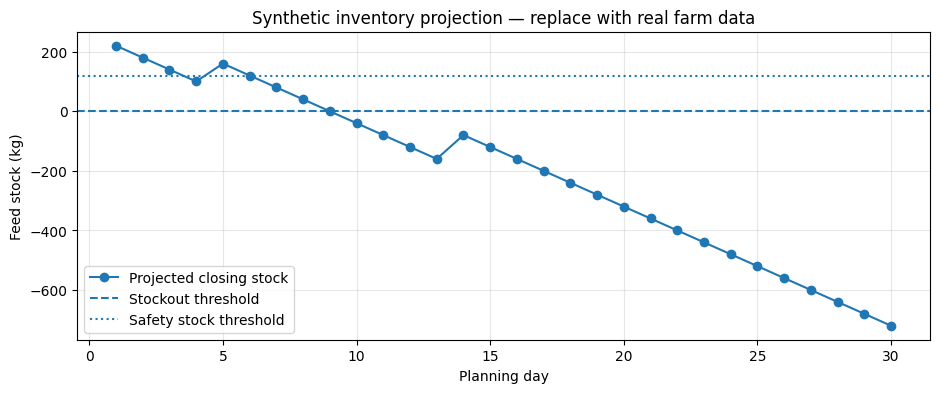

Projected shortage first occurs on day: 10


In [17]:
# SYNTHETIC DEMO VALUES — replace with real farm records when available
planning_days = 30
daily_consumption_kg = 40.0
opening_stock_kg = 260.0
safety_stock_days = 3
# Example scheduled deliveries (day number: delivered kg)
deliveries = {5: 100.0, 14: 120.0}

rows = []
stock = opening_stock_kg
for day in range(1, planning_days + 1):
    received = deliveries.get(day, 0.0)
    opening = stock
    stock = opening + received - daily_consumption_kg
    rows.append({
        "day": day,
        "opening_stock_kg": opening,
        "incoming_kg": received,
        "daily_consumption_kg": daily_consumption_kg,
        "closing_stock_kg": stock,
        "shortage": stock < 0,
        "below_safety_stock": stock < daily_consumption_kg * safety_stock_days
    })

inventory_projection = pd.DataFrame(rows)
display(inventory_projection.head(15))

plt.figure(figsize=(11, 4))
plt.plot(inventory_projection["day"], inventory_projection["closing_stock_kg"], marker="o", label="Projected closing stock")
plt.axhline(0, linestyle="--", label="Stockout threshold")
plt.axhline(daily_consumption_kg * safety_stock_days, linestyle=":", label="Safety stock threshold")
plt.xlabel("Planning day")
plt.ylabel("Feed stock (kg)")
plt.title("Synthetic inventory projection — replace with real farm data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

stockout_rows = inventory_projection[inventory_projection["shortage"]]
if len(stockout_rows):
    print("Projected shortage first occurs on day:", int(stockout_rows.iloc[0]["day"]))
else:
    print("No projected negative stock in this scenario.")


## 6. First procurement calculation

A simple reorder trigger is:
`reorder_point = average_daily_demand * lead_time_days + safety_stock`.

This is a baseline policy to compare against the future optimization model. It assumes daily demand is known and does not yet optimize nutrient mix or uncertain delivery times.


In [18]:
avg_daily_demand_kg = 40.0       # synthetic
supplier_lead_time_days = 4       # synthetic
safety_stock_days = 3             # policy assumption

reorder_point_kg = avg_daily_demand_kg * supplier_lead_time_days + avg_daily_demand_kg * safety_stock_days
current_stock_kg = 260.0          # synthetic
target_coverage_days = 14         # policy assumption
target_stock_kg = avg_daily_demand_kg * target_coverage_days

recommended_order_kg = max(0.0, target_stock_kg - current_stock_kg)

print(f"Reorder point: {reorder_point_kg:.1f} kg")
print(f"Current stock: {current_stock_kg:.1f} kg")
print(f"Target stock for {target_coverage_days} days: {target_stock_kg:.1f} kg")
print(f"Baseline suggested order: {recommended_order_kg:.1f} kg")
print("\nReminder: synthetic demonstration only; do not use as a real feeding/purchasing recommendation.")


Reorder point: 280.0 kg
Current stock: 260.0 kg
Target stock for 14 days: 560.0 kg
Baseline suggested order: 300.0 kg

Reminder: synthetic demonstration only; do not use as a real feeding/purchasing recommendation.


## 7. Save outputs from Kaggle

Files will be saved under `/kaggle/working/livestock_preprocessed`. Download them from the notebook's Output panel after running the notebook.


In [19]:
print("Output files:")
for p in sorted(OUTPUT_ROOT.glob("*")):
    if p.is_file():
        print(p.name, "-", round(p.stat().st_size / 1024, 1), "KB")

print("\nNext steps:")
print("1. Inspect the ERA dictionary and validate nutrient code meanings/units.")
print("2. Verify ingredient mappings before joining price to nutrition.")
print("3. Obtain historical price records across multiple dates.")
print("4. Obtain farm inventory, consumption, orders and actual delivery data.")
print("5. Then build the multi-period supplier-aware optimization model.")


Output files:
feed_nutrients_clean_long.csv - 878.9 KB
feed_nutrients_clean_wide.csv - 249.3 KB
ingredient_crosswalk_review_required.csv - 0.5 KB
market_prices_feed_candidates.csv - 22.3 KB

Next steps:
1. Inspect the ERA dictionary and validate nutrient code meanings/units.
2. Verify ingredient mappings before joining price to nutrition.
3. Obtain historical price records across multiple dates.
4. Obtain farm inventory, consumption, orders and actual delivery data.
5. Then build the multi-period supplier-aware optimization model.


In [20]:
import os

OUTPUT_DIR = "/kaggle/working/livestock_preprocessed"

for root, dirs, files in os.walk(OUTPUT_DIR):
    for file in files:
        print(os.path.join(root, file))

/kaggle/working/livestock_preprocessed/ingredient_crosswalk_review_required.csv
/kaggle/working/livestock_preprocessed/feed_nutrients_clean_long.csv
/kaggle/working/livestock_preprocessed/feed_nutrients_clean_wide.csv
/kaggle/working/livestock_preprocessed/market_prices_feed_candidates.csv


In [21]:
import os
import shutil
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/livestock_preprocessed")
ZIP_PATH = "/kaggle/working/livestock_results.zip"

if not OUTPUT_DIR.exists():
    raise FileNotFoundError(
        f"Output folder not found: {OUTPUT_DIR}. "
        "Check the output directory used by your notebook."
    )

shutil.make_archive(
    ZIP_PATH.removesuffix(".zip"),
    "zip",
    root_dir=OUTPUT_DIR
)

print("ZIP created:", ZIP_PATH)
print("Size:", round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2), "MB")

ZIP created: /kaggle/working/livestock_results.zip
Size: 0.19 MB


In [23]:
from IPython.display import FileLink, display
import os

zip_path = "/kaggle/working/livestock_results.zip"

if os.path.exists(zip_path):
    display(FileLink(zip_path, result_html_prefix="Download your ZIP: "))
else:
    print("ZIP not found. Create the ZIP first.")

/kaggle/working/livestock_results.zip